In [41]:
import os
import sys 
print("Active Environment Path:", sys.executable)
import json
import subprocess
import tempfile
from pathlib import Path
import numpy as np
import pandas as pd
import geopandas as gpd
import xarray as xr
import matplotlib.pyplot as plt
from sklearn.metrics import f1_score, accuracy_score, confusion_matrix, PrecisionRecallDisplay
import pystac_client
import planetary_computer
import odc.stac
import rasterio.features

# local
os.chdir("/home/azureuser/EBRD_Tillage/AK_Experiments/AK_pipeline")
sys.path.append(os.getcwd())
from Generic.addSentinelIndices import calculateSentinelIndex, SENTINEL_INDEX_DEPENDENCIES

Active Environment Path: /anaconda/envs/geospatial-base/bin/python


In [42]:
# ==============================================================================
# 1. HELPER FUNCTIONS FOR IN-MEMORY STAC & RASTER REDUCTION
# ==============================================================================

def get_utm_crs(gdf: gpd.GeoDataFrame) -> str:
    """Determine the local UTM EPSG code from a GeoDataFrame centroid."""
    centroid = gdf.to_crs("EPSG:4326").union_all().centroid
    lon, lat = centroid.x, centroid.y
    zone = int((lon + 180) // 6) + 1
    epsg = 32600 + zone if lat >= 0 else 32700 + zone
    return f"EPSG:{epsg}"

def compute_event_band_in_memory( # In the future, make it band_list for efficiency when calculating multiple bands
    row: pd.Series,
    catalog_client: pystac_client.Client,
    band: str,
    buffer_days: int = 10,
    max_cloud_cover: int = 90,
    resolution: float = 10.0,
    tempAg: str='min',
    spatAg: str='mean'
) -> float:
    """Stream optical bands for a single event directly into memory and return

    the two-stage reduced NDVI: temporal min first, then spatial mean.
    """
    geom_4326 = row.geometry
    
    # 1. Date window with buffer
    #start_dt = (pd.to_datetime(row["start_date"]) - pd.Timedelta(days=buffer_days)).strftime("%Y-%m-%d")
    start_dt = pd.to_datetime(row["end_date"]).strftime("%Y-%m-%d")
    end_dt = (pd.to_datetime(row["end_date"]) + pd.Timedelta(days=buffer_days)).strftime("%Y-%m-%d")
    
    # 2. STAC Search directly in memory
    search = catalog_client.search(
        collections=["sentinel-2-l2a"],
        intersects=geom_4326.__geo_interface__,
        datetime=f"{start_dt}/{end_dt}",
        query={"eo:cloud_cover": {"lte": max_cloud_cover}},
        limit=100
    )
    items = list(search.items())
    
    if not items:
        return np.nan

    # Sign asset URLs for Planetary Computer Azure SAS authentication
    items = [planetary_computer.sign(item) for item in items]
    
    # 3. Project polygon to local UTM for accurate 10m spatial rasterization
    event_gdf = gpd.GeoDataFrame([row], crs="EPSG:4326")
    utm_crs = get_utm_crs(event_gdf)
    event_utm = event_gdf.to_crs(utm_crs)
    minx, miny, maxx, maxy = event_utm.total_bounds
    
    # 4. Calculate required bands and stream  directly into an xarray DataArray
    # (xarray chunks/streams directly from Azure Blob Storage COGs)
    bands_needed = SENTINEL_INDEX_DEPENDENCIES[band]
    ds = odc.stac.load(
        items,
        bands=bands_needed,
        crs=utm_crs,
        resolution=resolution,
        x=(minx - 20, maxx + 20),
        y=(miny - 20, maxy + 20),
        chunks={}
    ).load() # Materialize arrays into RAM

    if ds.sizes.get("time", 0) == 0:
        return np.nan

    # 5. Vectorized NDVI Calculation across 3D Array (time, y, x)
    # Apply ESA baseline offset correction if needed (>4000 DN)
    for band in bands_needed: 
        ds[band] = ds[band].astype("float32")

    
    band_stack = calculateSentinelIndex(ds,band)[band]
    
    
    # 6. Stage 1: Temporal Aggregation First (Temporal MIN per spatial pixel)
    if tempAg == 'min':
        band_aggregated_2d = band_stack.min(dim="time")
    else: 
        raise NotImplementedError
    
    # 7. Rasterize Field Polygon to Mask Pixels Outside Boundary
    transform = ds.odc.transform
    height, width = ds.sizes["y"], ds.sizes["x"]
    
    
    mask = rasterio.features.rasterize(
        [(geom, 1) for geom in event_utm.geometry],
        out_shape=(height, width),
        transform=transform,
        fill=0,
        dtype="uint8"
    )
    
    # 8. Stage 2: Spatial Aggregation (Spatial MEAN across polygon mask)
    masked_band = np.where(mask == 1, band_aggregated_2d.values, np.nan)
    if spatAg == 'mean':
        spatial_mean_band = np.nanmean(masked_band)
    else: 
        raise NotImplementedError 

    return float(spatial_mean_band)



In [43]:

RUN_ACQUIRE_PATH = Path("/home/azureuser/EBRD_Tillage/EBRD_tillage_monitoring-main/src/acquire/run_acquire.py")  
TEMP_DIR = Path("/home/azureuser/EBRD_Tillage/data/temp")
TEMP_DIR.mkdir(parents=True, exist_ok=True)
INPUT_DATA_PATH= Path("/home/azureuser/EBRD_Tillage/data/input/EBRD_merged_classified.shp")  

# Global Variables 
kind = 'Sentinel2' # Kinda useless now, only Sentinel 2 in VM
band = 'NDTI'
padding = 5
tempAg = 'min'
spatAg = 'mean'
classCol = 'Classifica'
stratified_limitation = -1


In [44]:
# ==============================================================================
# 1. SETUP & PATH CONFIGURATION
# ==============================================================================
print(f"Reading shapefile from: {INPUT_DATA_PATH}")
gdf = gpd.read_file(INPUT_DATA_PATH)
gdf=gdf.to_crs("EPSG:4326")
# Quick check
print(f"Successfully loaded {len(gdf)} rows.")
gdf = gdf.rename(columns={'Beginning':'start_date',"End date":'end_date'})
print(gdf.columns)
gdf["start_date"] = pd.to_datetime(gdf["start_date"])
gdf["end_date"] = pd.to_datetime(gdf["end_date"])
gdf = gdf[(gdf.Classifica == 'Conservation') | (gdf.Classifica == 'Conventional')]

if(stratified_limitation >0): 
    good = gdf[gdf.Classifica == 'Conservation' ].sample(stratified_limitation)
    bad = gdf[gdf.Classifica == 'Conventional'].sample(stratified_limitation)
    gdf = pd.concat([good,bad],ignore_index=True).reset_index() 
    
print(f"Filtered to {len(gdf)} rows.")


Reading shapefile from: /home/azureuser/EBRD_Tillage/data/input/EBRD_merged_classified.shp
Successfully loaded 5746 rows.
Index(['index', 'fid', 'Operation', 'Group of o', 'Machinery', 'Machine',
       'start_date', 'end_date', 'Field ID', 'Crop', 'Year', 'Area, ha',
       'operation_', 'source_fil', 'FieldAreaH', 'Completion', 'Classifica',
       'geometry'],
      dtype='str')
Filtered to 1790 rows.


In [45]:
# ==============================================================================
# 2. MAIN BATCH EXECUTION PIPELINE
# ==============================================================================
# Connect to Planetary Computer STAC Catalog ONCE
catalog_client = pystac_client.Client.open(
    "https://planetarycomputer.microsoft.com/api/stac/v1",
    modifier=planetary_computer.sign_inplace
)

print(f"Starting in-memory processing for {len(gdf)} tillage events...")

# Run in-memory extraction over events
band_results = []
for idx, row in gdf.iterrows():
    print(f"Processing Event {idx+1}/{len(gdf)}: {row['fid']} ({row['Classifica']})...", end="")
    try:
        band_val = compute_event_band_in_memory(row, catalog_client,band, buffer_days=10,tempAg='min',spatAg = 'mean')
        band_results.append(band_val)
        print(f" Done -> {band}: {band_val:.4f}")
    except Exception as e:
        print(f" Failed -> Error: {e}")
        band_results.append(np.nan)

gdf["summary_band"] = band_results

# Filter out failed/empty retrievals
analysis_df = gdf.dropna(subset=["summary_band"]).copy()

Starting in-memory processing for 1790 tillage events...
Processing Event 1/1790: 1.0 (Conservation)... Done -> NDTI: 1219.8486
Processing Event 3/1790: 4.0 (Conservation)... Done -> NDTI: 1219.8580
Processing Event 4/1790: 5.0 (Conservation)... Done -> NDTI: 1219.8486
Processing Event 5/1790: 6.0 (Conservation)... Done -> NDTI: 1219.8486
Processing Event 6/1790: 7.0 (Conservation)... Done -> NDTI: 1219.8580
Processing Event 7/1790: 8.0 (Conventional)... Done -> NDTI: 1219.8580
Processing Event 8/1790: 9.0 (Conventional)... Done -> NDTI: 1219.8580
Processing Event 9/1790: 10.0 (Conventional)... Done -> NDTI: 1219.8580
Processing Event 10/1790: 13.0 (Conventional)... Done -> NDTI: 1965.0211
Processing Event 13/1790: 27.0 (Conservation)... Done -> NDTI: 2562.6208
Processing Event 14/1790: 28.0 (Conservation)... Done -> NDTI: 2562.6208
Processing Event 15/1790: 29.0 (Conservation)... Done -> NDTI: 1988.6494
Processing Event 56/1790: 172.0 (Conventional)... Done -> NDTI: nan
Processing Eve


================ OPTIMIZATION RESULTS ================
Optimal NDTI Threshold: 565.4349
Maximized F1-Score:     0.7793
Overall Accuracy:       0.6385


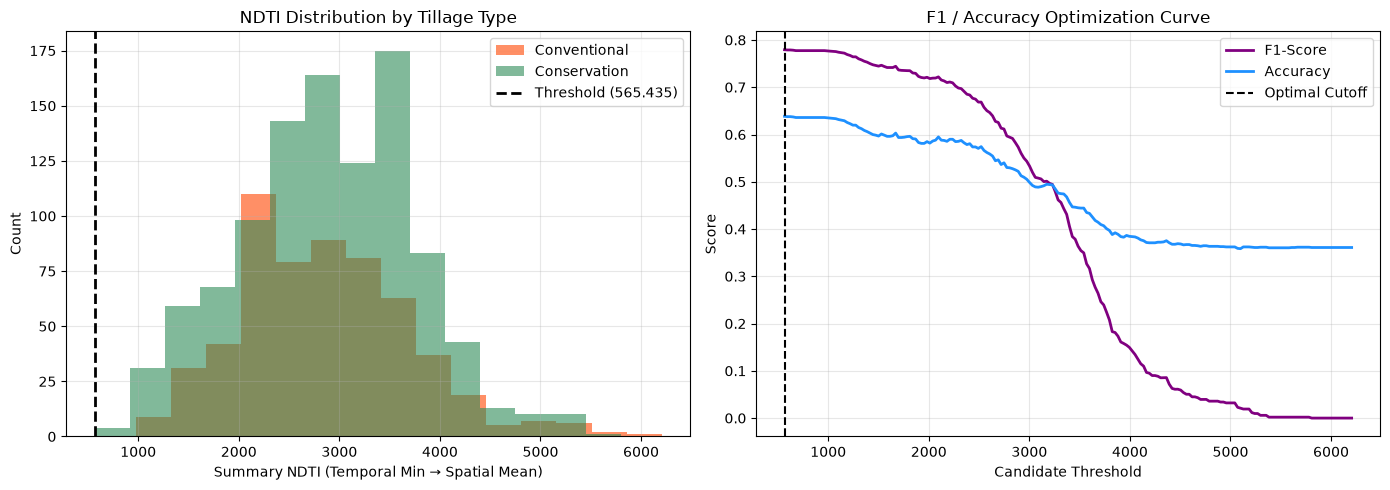

In [46]:

# ==============================================================================
# 3. THRESHOLD OPTIMIZATION & VISUALIZATION
# ==============================================================================

# Encode target: Conventional = 0, Conservation = 1
analysis_df["binary_target"] = (analysis_df["Classifica"].str.lower() == "conservation").astype(int)

y_true = analysis_df["binary_target"].values
scores = analysis_df["summary_band"].values

candidate_thresholds = np.linspace(scores.min(), scores.max(), 200)

best_f1, best_acc, best_threshold = -1.0, -1.0, candidate_thresholds[0]
f1_scores, acc_scores = [], []

for t in candidate_thresholds:
    y_pred = (scores >= t).astype(int)
    f1 = f1_score(y_true, y_pred, zero_division=0)
    acc = accuracy_score(y_true, y_pred)
    
    f1_scores.append(f1)
    acc_scores.append(acc)
    
    #if f1 > best_f1 or (f1 == best_f1 and acc > best_acc):
    if acc > best_acc or (f1 > best_f1 and acc == best_acc):
        best_f1, best_acc, best_threshold = f1, acc, t

print("\n================ OPTIMIZATION RESULTS ================")
print(f"Optimal {band} Threshold: {best_threshold:.4f}")
print(f"Maximized F1-Score:     {best_f1:.4f}")
print(f"Overall Accuracy:       {best_acc:.4f}")
print("======================================================")

# Plot distributions and optimization curve
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5))

conv_scores = analysis_df[analysis_df["binary_target"] == 0]["summary_band"]
cons_scores = analysis_df[analysis_df["binary_target"] == 1]["summary_band"]

ax1.hist(conv_scores, bins=15, alpha=0.6, color="orangered", label="Conventional")
ax1.hist(cons_scores, bins=15, alpha=0.6, color="seagreen", label="Conservation")
ax1.axvline(best_threshold, color="black", linestyle="--", linewidth=2, label=f"Threshold ({best_threshold:.3f})")
ax1.set_xlabel(f"Summary {band} (Temporal Min → Spatial Mean)")
ax1.set_ylabel("Count")
ax1.set_title(f"{band} Distribution by Tillage Type")
ax1.legend()
ax1.grid(True, alpha=0.3)

ax2.plot(candidate_thresholds, f1_scores, color="purple", label="F1-Score", linewidth=2)
ax2.plot(candidate_thresholds, acc_scores, color="dodgerblue", label="Accuracy", linewidth=2)
ax2.axvline(best_threshold, color="black", linestyle="--", linewidth=1.5, label="Optimal Cutoff")
ax2.set_xlabel("Candidate Threshold")
ax2.set_ylabel("Score")
ax2.set_title("F1 / Accuracy Optimization Curve")
ax2.legend()
ax2.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()